# Importing và khai báo config

In [10]:

from pathlib import Path
from types import SimpleNamespace
import platform
import time
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import average_precision_score
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

# Project paths
ROOT = Path.cwd().resolve()
INTERIM = ROOT / "data" / "interim"
REPORTS = ROOT / "reports"
TABLES = REPORTS / "tables"
FIGS = REPORTS / "figures"

# Configuration
C = SimpleNamespace(
    ROOT=ROOT,
    INTERIM=INTERIM,
    REPORTS=REPORTS,
    TABLES=TABLES,
    FIGS=FIGS,
    BRAKE_RATES=(0.10, 0.20, 0.30),
    RULE_K=(3, 5, 7, 10),
    F1_FEATURES=["logk", "log_gap", "accel", "log_since_r1"],
    SEED=42,
    HORIZON=5,
    DEEP_M=7,
)

# Check source data
samples_path = INTERIM / "samples.parquet"
m1_path = INTERIM / "m1_clean.parquet"

if not INTERIM.is_dir():
    raise FileNotFoundError(f"Data directory not found: {INTERIM}")

print(f"Project: {ROOT}")
print(f"Inputs: {samples_path} | {m1_path}")

if not samples_path.is_file():
    raise FileNotFoundError(f"File not found: {samples_path}")

if not m1_path.is_file():
    raise FileNotFoundError(f"File not found: {m1_path}")


Project: D:\Academic\UET\ATCS\shock-detector
Inputs: D:\Academic\UET\ATCS\shock-detector\data\interim\samples.parquet | D:\Academic\UET\ATCS\shock-detector\data\interim\m1_clean.parquet


# Gắn dữ liệu M1 gần nhất đã đóng vào các event

In [11]:
ONE_MIN = pd.Timedelta(minutes=1)

def decision_bar_key(t: pd.Series, offset=pd.Timedelta(0)) -> pd.Series:
    """Giờ mở của nến M1 mới nhất ĐÃ ĐÓNG tại thời điểm t (theo đồng hồ M1).
    = floor(t + offset, phút) − 1 phút.  Nến floor(t) đang chạy → loại."""
    return (pd.to_datetime(t).astype("datetime64[ns]") + offset).dt.floor("min") - ONE_MIN

def attach_last_closed(events: pd.DataFrame, m1: pd.DataFrame, time_col: str = "timestamp",
                       cols=("close",), offset=pd.Timedelta(0), prefix: str = "m1_") -> pd.DataFrame:
    """Gắn vào mỗi sự kiện giá trị của nến M1 mới nhất đã đóng trước t.

    m1: DataFrame có cột `time` (giờ mở nến) + các cột cần gắn (giá hoặc đặc trưng
        nhân quả đã tính sẵn trên M1).
    Trả về bản sao `events` (giữ thứ tự) thêm:
      {prefix}bar_time : giờ mở nến được dùng (luôn ≤ floor(t+offset) − 1 phút)
      {prefix}pos      : vị trí dòng của nến đó trong m1 (để tính cửa sổ lùi về quá khứ)
      {prefix}bar_age_min : số phút từ nến đó đến nến lẽ ra phải dùng
                            (0 = liền trước; >0 = đang trong khoảng trống, ví dụ sau cuối tuần)
      {prefix}<col>    : giá trị cột
    """
    m = m1[["time", *cols]].copy()
    m["time"] = m["time"].astype("datetime64[ns]")
    m["_pos"] = np.arange(len(m))
    if not m["time"].is_monotonic_increasing:
        raise ValueError("m1 phải sắp xếp tăng dần theo time")
    ev = events.copy()
    ev["_key"] = decision_bar_key(ev[time_col], offset)
    ev["_order"] = np.arange(len(ev))
    # backward + allow_exact_matches: lấy nến có giờ mở ≤ key, KHÔNG BAO GIỜ lấy nến sau key
    j = pd.merge_asof(ev.sort_values("_key")[["_key", "_order"]], m.rename(columns={"time": "_bar"}),
                      left_on="_key", right_on="_bar", direction="backward", allow_exact_matches=True)
    j = j.sort_values("_order").set_index(ev.index)
    ev[f"{prefix}bar_time"] = j["_bar"]
    ev[f"{prefix}pos"] = j["_pos"].astype("Int64")
    ev[f"{prefix}bar_age_min"] = (j["_key"] - j["_bar"]).dt.total_seconds().div(60)
    for c in cols:
        ev[f"{prefix}{c}"] = j[c]
    return ev.drop(columns=["_key", "_order"])


# Xây dựng đặc trưng data cho M1 cho mô hình, thuộc volatility và trend

tính đặc trưng từng nến, ghép vào sự kiện, sau đó chuẩn hóa volatility theo từng fold, rồi validate lại và evaluate

In [12]:
"""G4 — Đặc trưng M1: họ 2 (volatility) và họ 3 (trend).

Đại diện (mỗi họ 1 biến vào mô hình chính):
  họ 2  vol_z = (log RV30 − μ_h) / σ_h   (Andersen & Bollerslev 1997, bản đơn giản theo giờ)
        RV30 = sqrt(Σ r²) của 30 return 1 phút; μ_h, σ_h = mean/std của log RV30 theo giờ server,
        fit trên M1 từ 02 đến HẾT THÁNG TRAIN của từng fold (không dùng tháng test).
  họ 3  ser60 = sign · (C_b − C_{b−60}) / Σ|ΔC| trên 60 phút   (efficiency ratio Kaufman, có dấu)
        ∈ [−1, 1]; < 0 = giá đi ngược basket; |ser60| = ER60 (độ "thẳng" của đường giá).
  Biến chỉ dùng cho độ nhạy: ser30, ret60_z = sign · Σr / sqrt(Σr²) trên 60 phút (dạng MOP 2012).

Chống nhìn tương lai:
  - Đặc trưng theo từng nến b chỉ dùng nến ≤ b (cumsum lùi), tính trên M1 trước khi ghép.
  - Ghép với nhãn CHỈ qua m1.attach_last_closed (nến mở ≤ floor(t) − 1 phút), offset = 0 (G3).
  - Cửa sổ n return phải gồm n+1 nến liên tục (gap_min = 1); nếu không → NaN.
  - Nến liền trước không tồn tại (bar_age_min > 0) → NaN (quyết định G4 mục 13.3).
"""

import numpy as np
import pandas as pd


RV_WIN = 30
TREND_WIN = 60
TREND_WIN_SHORT = 30
BAR_COLS = ("lrv30", "ser60", "ser30", "ret60_z")
MAIN_FEATURES = {"vol": ["vol_z"], "trend": ["ser60"]}


def _contig_run(gap_min: np.ndarray) -> np.ndarray:
    """Số return 1 phút liên tục kết thúc tại mỗi nến (0 ở nến đầu / ngay sau khoảng trống)."""
    ok = np.nan_to_num(gap_min, nan=0.0) == 1
    run = np.zeros(len(ok), dtype=np.int64)
    c = 0
    for i, v in enumerate(ok):
        c = c + 1 if v else 0
        run[i] = c
    return run


def _win_sum(x: np.ndarray, n: int) -> np.ndarray:
    """Tổng n phần tử kết thúc tại i (gồm i): cs[i] − cs[i−n]. NaN khi i < n."""
    cs = np.concatenate([[0.0], np.cumsum(x)])
    out = np.full(len(x), np.nan)
    out[n - 1:] = cs[n:] - cs[:-n]
    return out


def bar_features(m1: pd.DataFrame) -> pd.DataFrame:
    """Đặc trưng theo nến, chỉ dùng nến ≤ chính nó. m1 có time, close, gap_min, sắp xếp tăng dần.
    ser*, ret60_z chưa nhân dấu basket (dấu thị trường: > 0 = giá tăng)."""
    t = m1["time"].astype("datetime64[ns]")
    if not t.is_monotonic_increasing:
        raise ValueError("m1 phải sắp xếp tăng dần theo time")
    c = m1["close"].to_numpy(float)
    lc = np.log(c)
    run = _contig_run(m1["gap_min"].to_numpy(float))
    r = np.diff(lc, prepend=np.nan)
    dc = np.diff(c, prepend=np.nan)
    bad = run == 0
    r = np.where(bad, 0.0, r)
    dc = np.where(bad, 0.0, dc)

    def valid(n):
        return run >= n

    out = pd.DataFrame({"time": t.to_numpy()})
    rv30 = np.sqrt(_win_sum(r ** 2, RV_WIN))
    out["lrv30"] = np.where(valid(RV_WIN) & (rv30 > 0), np.log(np.where(rv30 > 0, rv30, 1.0)), np.nan)
    for n, name in ((TREND_WIN, "ser60"), (TREND_WIN_SHORT, "ser30")):
        net = _win_sum(dc, n)
        path = _win_sum(np.abs(dc), n)
        out[name] = np.where(valid(n) & (path > 0), net / np.where(path > 0, path, 1.0), np.nan)
    s1, s2 = _win_sum(r, TREND_WIN), _win_sum(r ** 2, TREND_WIN)
    out["ret60_z"] = np.where(valid(TREND_WIN) & (s2 > 0), s1 / np.sqrt(np.where(s2 > 0, s2, 1.0)), np.nan)
    out["hour"] = t.dt.hour.to_numpy()
    return out


def fit_hour_norm(bars: pd.DataFrame, cutoff) -> pd.DataFrame:
    """μ_h, σ_h của lrv30 theo giờ server, CHỈ trên nến có time < cutoff (đầu tháng test)."""
    b = bars[(bars["time"] < pd.Timestamp(cutoff)) & bars["lrv30"].notna()]
    return b.groupby("hour")["lrv30"].agg(mu="mean", sd="std", n="size")


def apply_hour_norm(lrv: pd.Series, hour: pd.Series, norm: pd.DataFrame) -> pd.Series:
    mu = hour.map(norm["mu"])
    sd = hour.map(norm["sd"])
    return (lrv - mu) / sd


def attach_features(samples: pd.DataFrame, bars: pd.DataFrame, offset=pd.Timedelta(0)) -> pd.DataFrame:
    """Gắn đặc trưng của nến đã đóng gần nhất; nhân dấu basket (BUY +1, SELL −1).
    Trả bản sao samples + m1_bar_time, m1_bar_age_min, hour, lrv30, ser60, ser30, ret60_z, m1_ok."""
    ev = attach_last_closed(samples, bars, time_col="timestamp", cols=(*BAR_COLS, "hour"),
                            offset=offset, prefix="m1_")
    sign = np.where(ev["side"].astype(str).str.upper() == "BUY", 1.0, -1.0)
    out = samples.copy()
    out["m1_bar_time"] = ev["m1_bar_time"]
    out["m1_bar_age_min"] = ev["m1_bar_age_min"]
    out["hour"] = ev["m1_hour"]
    out["lrv30"] = ev["m1_lrv30"]
    for c in ("ser60", "ser30", "ret60_z"):
        out[c] = ev[f"m1_{c}"] * sign
    out.loc[out["m1_bar_age_min"] != 0, ["lrv30", "ser60", "ser30", "ret60_z"]] = np.nan
    out["m1_ok"] = out[["lrv30", "ser60", "ser30", "ret60_z"]].notna().all(axis=1)
    return out


def with_fold_vol(samples: pd.DataFrame, bars: pd.DataFrame, test_month: str):
    """Bản sao samples có vol_z chuẩn hóa bằng μ_h, σ_h fit trên M1 trước tháng test."""
    norm = fit_hour_norm(bars, pd.Timestamp(test_month + "-01"))
    s = samples.copy()
    s["vol_z"] = apply_hour_norm(s["lrv30"], s["hour"], norm)
    return s, norm


def check_decision_bar(feat: pd.DataFrame) -> int:
    """Số dòng vi phạm: nến dùng phải ĐÓNG trước t, tức bar_time + 1 phút ≤ t."""
    ok = feat["m1_bar_time"].isna() | (feat["m1_bar_time"] + pd.Timedelta(minutes=1) <= feat["timestamp"])
    return int((~ok).sum())


def check_truncation(m1: pd.DataFrame, cuts) -> float:
    """Đặc trưng nến ≤ cut tính trên M1 bị cắt tại cut phải trùng bản đầy đủ. Trả max |chênh|."""
    full = bar_features(m1)
    worst = 0.0
    for cut in cuts:
        part = bar_features(m1[m1["time"] <= cut].reset_index(drop=True))
        a = full.loc[full["time"] <= cut, BAR_COLS].to_numpy()
        b = part[list(BAR_COLS)].to_numpy()
        if not np.array_equal(np.isnan(a), np.isnan(b)):
            return np.inf
        d = np.nanmax(np.abs(a - b)) if np.isfinite(a).any() else 0.0
        worst = max(worst, float(d))
    return worst


def check_perturb_future(samples: pd.DataFrame, m1: pd.DataFrame, events_idx, seed=0) -> tuple[int, int]:
    """Với mỗi sự kiện: làm nhiễu MỌI nến có giờ mở ≥ floor(t) (nến đang chạy + tương lai),
    tính lại đặc trưng. Trả (số sự kiện đặc trưng bị đổi — phải 0, số sự kiện kế tiếp bị đổi — nên > 0)."""
    rng = np.random.default_rng(seed)
    cols = ["lrv30", "ser60", "ser30", "ret60_z"]
    base = attach_features(samples, bar_features(m1))
    changed, sensitive = 0, 0
    for i in events_idx:
        t_floor = samples.loc[i, "timestamp"].floor("min")
        m = m1.copy()
        fut = m["time"] >= t_floor
        m.loc[fut, "close"] = m.loc[fut, "close"] * np.exp(rng.normal(0, 2e-3, int(fut.sum())))
        new = attach_features(samples, bar_features(m))
        a, b = base.loc[i, cols].to_numpy(float), new.loc[i, cols].to_numpy(float)
        if not np.allclose(a, b, equal_nan=True, rtol=0, atol=1e-12):
            changed += 1
        # độ nhạy của test: một sự kiện sau t + 2 phút phải đổi
        later = samples.index[(samples["timestamp"] >= t_floor + pd.Timedelta(minutes=3))
                              & base["m1_ok"]]
        if len(later):
            j = later[np.argmin(samples.loc[later, "timestamp"].to_numpy())]
            if not np.allclose(base.loc[j, cols].to_numpy(float), new.loc[j, cols].to_numpy(float),
                               equal_nan=True, rtol=0, atol=1e-12):
                sensitive += 1
    return changed, sensitive


def check_norm_no_test(bars: pd.DataFrame, cutoff, seed=0) -> float:
    """μ_h, σ_h không đổi khi làm nhiễu lrv30 của nến ≥ cutoff. Trả max |chênh|."""
    a = fit_hour_norm(bars, cutoff)
    b2 = bars.copy()
    m = b2["time"] >= pd.Timestamp(cutoff)
    b2.loc[m, "lrv30"] = b2.loc[m, "lrv30"] + np.random.default_rng(seed).normal(0, 5, int(m.sum()))
    b = fit_hour_norm(b2, cutoff)
    return float(np.nanmax(np.abs(a[["mu", "sd"]].to_numpy() - b[["mu", "sd"]].to_numpy())))


def steps_last_60m(samples: pd.DataFrame) -> pd.Series:
    """Số bậc của chính basket mở trong (t − 60 phút, t], gồm Rk hiện tại và R1 nếu trong cửa sổ."""
    out = pd.Series(0, index=samples.index, dtype="int64")
    w = np.int64(60 * 60 * 10**9)
    for _, d in samples.groupby("basket_id", sort=False):
        ts = d["timestamp"].to_numpy().astype("datetime64[ns]").astype("int64")
        o = np.argsort(ts)
        tss = ts[o]
        cnt = np.searchsorted(tss, tss, "right") - np.searchsorted(tss, tss - w, "right")
        since_r1 = np.expm1(d["log_since_r1"].to_numpy()[o])     # phút
        cnt = cnt + (since_r1 < 60)
        out.loc[d.index[o]] = cnt
    return out

def walk_forward_m1(samples: pd.DataFrame, bars: pd.DataFrame, test_months, features, **kw):
    """Gọi evaluate.walk_forward từng tháng một; trước mỗi fold tính lại vol_z bằng μ_h, σ_h
    fit trên M1 < đầu tháng test. Train và test của fold dùng cùng một chuẩn hóa (chỉ từ quá khứ).
    Thứ tự dòng đầu ra giống walk_forward(samples, test_months, ...)."""
    outs = []
    for m in test_months:
        s = with_fold_vol(samples, bars, m)[0] if "vol_z" in (features or []) else samples
        if features is not None and s[features].isna().any().any():
            raise ValueError(f"NaN trong đặc trưng ở fold {m}; lọc dòng trước khi gọi")
        outs.append(walk_forward(s, [m], features=features, **kw))
    return pd.concat(outs, ignore_index=True)

F = SimpleNamespace(**{"RV_WIN": RV_WIN, "TREND_WIN": TREND_WIN, "TREND_WIN_SHORT": TREND_WIN_SHORT, "BAR_COLS": BAR_COLS, "MAIN_FEATURES": MAIN_FEATURES, "_contig_run": _contig_run, "_win_sum": _win_sum, "bar_features": bar_features, "fit_hour_norm": fit_hour_norm, "apply_hour_norm": apply_hour_norm, "attach_features": attach_features, "with_fold_vol": with_fold_vol, "check_decision_bar": check_decision_bar, "check_truncation": check_truncation, "check_perturb_future": check_perturb_future, "check_norm_no_test": check_norm_no_test, "steps_last_60m": steps_last_60m, "walk_forward_m1": walk_forward_m1})


# Đánh giá mô hình

walkforward theo tháng, tạo score và chọn threshold, rồi đánh giá prauc

kiểm tra xem mô hình có dự đoán được những basket đi vào vùng rủi ro cao, kết quả có ổn định; và nếu kích hoạt halt thì có thể tránh mở thêm bao bậc

In [13]:
"""Khung đánh giá: walk-forward theo tháng, PR-AUC, bootstrap theo ngày, mô phỏng phanh."""
import numpy as np
import pandas as pd
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import average_precision_score
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler



def make_fold(samples, month):
    """Train = dòng của các tháng trước, loại basket kết thúc sau mốc cắt (purge).
    Test = dòng thuộc tháng `month`."""
    ms = pd.Timestamp(month + "-01")
    train = samples[samples["t_end"] < ms]
    test = samples[samples["month"] == month]
    n_purged = int(((samples["timestamp"] < ms) & (samples["t_end"] >= ms)).sum())
    return train, test, n_purged


def walk_forward(samples, test_months, features=None, rates=C.BRAKE_RATES, C_reg=1.0):
    """features=None -> luật theo độ sâu (score = k). Ngược lại logistic L2.
    Ngưỡng cho từng tỷ lệ phanh được chọn trên TRAIN, không dùng test."""
    outs = []
    for m in test_months:
        tr, te, _ = make_fold(samples, m)
        if len(te) == 0 or len(tr) == 0:
            continue
        if features is None:
            s_tr, s_te = tr["k"].to_numpy(float), te["k"].to_numpy(float)
        else:
            pipe = make_pipeline(StandardScaler(), LogisticRegression(C=C_reg, max_iter=1000))
            pipe.fit(tr[features], tr["y"])
            s_tr = pipe.predict_proba(tr[features])[:, 1]
            s_te = pipe.predict_proba(te[features])[:, 1]
        o = te[["basket_id", "k", "y", "M", "month", "day"]].copy()
        o["score"] = s_te
        for q in rates:
            o[f"thr_{round(q * 100)}"] = np.quantile(s_tr, 1 - q)
        o["fold"] = m
        outs.append(o)
    return pd.concat(outs, ignore_index=True)


def pr_auc(y, s):
    y = np.asarray(y)
    return float("nan") if y.sum() == 0 else float(average_precision_score(y, s))


def paired_bootstrap(y, s_a, s_b, groups, n_boot=1000, seed=C.SEED):
    """Bootstrap theo cụm (ngày), ghép cặp hai mô hình trên cùng mẫu lặp."""
    y, s_a, s_b = map(np.asarray, (y, s_a, s_b))
    codes, uniq = pd.factorize(np.asarray(groups))
    idx_by = [np.flatnonzero(codes == i) for i in range(len(uniq))]
    rng = np.random.default_rng(seed)
    a, b = [], []
    for _ in range(n_boot):
        pick = rng.integers(0, len(uniq), len(uniq))
        idx = np.concatenate([idx_by[i] for i in pick])
        if y[idx].sum() == 0:
            continue
        a.append(average_precision_score(y[idx], s_a[idx]))
        b.append(average_precision_score(y[idx], s_b[idx]))
    a, b = np.array(a), np.array(b)
    ci = lambda x: (float(np.percentile(x, 2.5)), float(np.percentile(x, 97.5)))
    return dict(ap_a=pr_auc(y, s_a), ci_a=ci(a), ap_b=pr_auc(y, s_b), ci_b=ci(b),
                delta=pr_auc(y, s_a) - pr_auc(y, s_b), ci_delta=ci(a - b),
                frac_delta_pos=float((a - b > 0).mean()), n_boot=len(a))


def brake_sim(oos, thr):
    """HALT tại dòng đầu tiên có score >= thr trong mỗi basket (tuần tự).
    avoided = M - k + 1: số bậc Rk..RM không được mở. Đây là CẬN TRÊN, không phải giảm lỗ.
    'Bắt kịp' = HALT đầu tiên rơi vào dòng y = 1 (còn >= 5 bậc nữa)."""
    d = oos[["basket_id", "k", "y", "M", "score"]].copy()
    d["flag"] = d["score"].to_numpy() >= np.asarray(thr)
    b = d.groupby("basket_id", sort=False).agg(M=("M", "first"))
    first = (d[d["flag"]].sort_values(["basket_id", "k"]).groupby("basket_id", sort=False)
             .first()[["k", "y"]].rename(columns={"k": "k_halt", "y": "y_halt"}))
    b = b.join(first)
    halted = b["k_halt"].notna()
    deep = b["M"] >= C.DEEP_M
    avoided = (b["M"] - b["k_halt"] + 1).where(halted, 0)
    n_b, n_deep = len(b), int(deep.sum())
    caught = int(((b["y_halt"] == 1) & deep).sum())
    false_h = int((b["y_halt"] == 0).sum())
    return dict(
        brake_rate_rows=float(d["flag"].mean()),
        n_baskets=n_b, n_deep=n_deep,
        halted_pct=float(halted.mean()),
        deep_caught=caught,
        deep_caught_pct=caught / n_deep if n_deep else float("nan"),
        avoided_total=int(avoided.sum()),
        avoided_pct=float(avoided.sum() / max((b["M"] - 1).sum(), 1)),
        avoided_deep=int(avoided[deep].sum()),
        false_flag_rows=int((d["flag"] & (d["y"] == 0)).sum()),
        false_halts=false_h,
        false_halts_per100=100 * false_h / n_b,
    )

E = SimpleNamespace(**{"make_fold": make_fold, "walk_forward": walk_forward, "pr_auc": pr_auc, "paired_bootstrap": paired_bootstrap, "brake_sim": brake_sim})


# Tạo thêm đặc trưng để thử nghiệm cải thiện

c1: xu hướng có dấu trong 4 giờ
c2: mức độ giá đi ngược basket kể từ R1
c3: khoảng cách đến đỉnh/đáy 4h theo hướng bất lợi

In [14]:
"""G5 khám phá — 3 ứng viên chốt TRƯỚC khi chạy (không chỉnh tham số sau khi xem kết quả).

Tất cả tính nhân quả trên M1: đặc trưng của nến b chỉ dùng nến ≤ b; ghép vào recovery tại t
CHỈ qua m1.attach_last_closed (nến mở ≤ floor(t) − 1 phút), offset 0 (G3).

Phân đoạn: M1 chia thành đoạn tại khoảng trống > SEG_GAP_MIN (cuối tuần). Nghỉ đêm (~1 giờ) nằm TRONG
đoạn (khác quy tắc "liên tục tuyệt đối" của G4, vì quy tắc đó loại mọi dòng trong 4 giờ đầu phiên).
Cửa sổ cần đủ W + 1 nến trong cùng đoạn; thiếu → NaN → dòng bị loại (báo số lượng).

  C1  ser240_s = sign · (C_b − C_{b−W}) / Σ|ΔC|   (W = 240 nến ≈ 4 giờ; efficiency ratio có dấu, như ser60)
  C2  exc      = asinh( sign · (C_R1 − C_t) / ATR60 )
        C_R1 = close nến đóng cuối cùng trước thời điểm R1 (R1 = t − expm1(log_since_r1) phút),
        C_t = close nến đóng gần nhất trước t, ATR60 = trung bình (H − L) 60 nến cuối.
        > 0 = giá đã đi ngược basket kể từ R1, tính theo đơn vị biên độ M1.
  C3  brk      = log1p( d / ATR60 ),  d = C_t − min(L, W nến) với BUY;  max(H, W nến) − C_t với SELL.
        nhỏ = giá đang sát đỉnh/đáy 4 giờ NGƯỢC basket (phá vỡ).
"""

import numpy as np
import pandas as pd


W = 240
ATR_N = 60
SEG_GAP_MIN = 360
BAR_X = ("close", "atr60", "ser240", "lo240", "hi240")


def extra_bar_features(m1: pd.DataFrame, w: int = W, atr_n: int = ATR_N, seg_gap_min: float = SEG_GAP_MIN) -> pd.DataFrame:
    t = m1["time"].astype("datetime64[ns]")
    if not t.is_monotonic_increasing:
        raise ValueError("m1 phải sắp xếp tăng dần theo time")
    c = m1["close"].to_numpy(float)
    gap = m1["gap_min"].to_numpy(float)
    new_seg = np.isnan(gap) | (gap > seg_gap_min)
    seg = np.cumsum(new_seg)
    pos = pd.Series(np.arange(len(m1))).groupby(seg).cumcount().to_numpy()
    dc = np.where(new_seg, 0.0, np.diff(c, prepend=np.nan))
    cs = np.concatenate([[0.0], np.cumsum(np.abs(dc))])
    path = np.full(len(c), np.nan)
    path[w:] = cs[w + 1:] - cs[1:len(c) - w + 1]
    net = np.full(len(c), np.nan)
    net[w:] = c[w:] - c[:-w]
    ok = pos >= w
    ser = np.where(ok & (path > 0), net / np.where(path > 0, path, 1.0), np.nan)
    g = pd.DataFrame({"h": m1["high"].to_numpy(float), "l": m1["low"].to_numpy(float), "seg": seg})
    rng = g["h"] - g["l"]
    atr = rng.groupby(g["seg"]).transform(lambda s: s.rolling(atr_n, min_periods=atr_n).mean())
    lo = g["l"].groupby(g["seg"]).transform(lambda s: s.rolling(w + 1, min_periods=w + 1).min())
    hi = g["h"].groupby(g["seg"]).transform(lambda s: s.rolling(w + 1, min_periods=w + 1).max())
    return pd.DataFrame({"time": t.to_numpy(), "close": c, "atr60": atr.to_numpy(), "ser240": ser,
                         "lo240": lo.to_numpy(), "hi240": hi.to_numpy()})


def attach_extra(samples: pd.DataFrame, xbars: pd.DataFrame) -> pd.DataFrame:
    """Trả DataFrame (index = samples.index): ser240_s, exc, brk, x_ok. Chỉ dùng nến đã đóng trước t
    (C3, C1) và nến đã đóng trước R1 (C2)."""
    sign = np.where(samples["side"].astype(str).str.upper() == "BUY", 1.0, -1.0)
    now = attach_last_closed(samples, xbars, time_col="timestamp", cols=BAR_X, prefix="x_")
    ev1 = samples[["timestamp", "log_since_r1"]].copy()
    ev1["timestamp"] = samples["timestamp"] - pd.to_timedelta(np.expm1(samples["log_since_r1"].to_numpy()), unit="m")
    r1 = attach_last_closed(ev1, xbars, time_col="timestamp", cols=("close",), prefix="r1_")
    bad = (now["x_bar_age_min"] != 0) | (r1["r1_bar_age_min"] != 0)
    atr = now["x_atr60"]
    out = pd.DataFrame(index=samples.index)
    out["ser240_s"] = now["x_ser240"] * sign
    out["exc"] = np.arcsinh(sign * (r1["r1_close"] - now["x_close"]) / atr)
    d = np.where(sign > 0, now["x_close"] - now["x_lo240"], now["x_hi240"] - now["x_close"])
    out["brk"] = np.log1p(np.clip(d, 0, None) / atr)
    out.loc[bad, ["ser240_s", "exc", "brk"]] = np.nan
    out["x_bar_time"] = now["x_bar_time"]
    out["x_ok"] = out[["ser240_s", "exc", "brk"]].notna().all(axis=1)
    return out

X = SimpleNamespace(**{"W": W, "ATR_N": ATR_N, "SEG_GAP_MIN": SEG_GAP_MIN, "BAR_X": BAR_X, "extra_bar_features": extra_bar_features, "attach_extra": attach_extra})


# Thí nghiệm

so sánh các quy tắc phanh basket, đánh giá mô hình theo thời gian, kiểm tra xem cảnh báo có thực sự tránh mở các bậc rủi ro

In [15]:
"""G6 — Quy tắc quyết định A/B, đối chứng, purge, phân tầng k, độ nhạy, case study 05/08.

THAM SỐ CHỐT TRƯỚC KHI XEM TEST (không chỉnh sau khi chạy):
  RATES = 10/20/30% (báo cáo); GRID = 5%…40% bước 5% (đường cong công bằng);
  M_LIMIT = 2; TAU_H_FRAC = 1/2 (chính), TAU_H_SENS = 1/3 (chỉ độ nhạy).

Quy ước mô phỏng (giống evaluate.brake_sim): dòng k = thời điểm bot SẮP mở Rk.
  HALT tại dòng j  ⇒ không mở Rj trở đi; bậc tránh được = M − j + 1 (cận trên);
  phanh nhầm = HALT tại j với M − j < HORIZON (tức y_j = 0).

Quy tắc A (một ngưỡng τ_L): HALT tại dòng đầu tiên có score ≥ τ_L.
Quy tắc B (hai ngưỡng τ_H ≥ τ_L, chung τ_L với A):
  - dòng đầu tiên có score ≥ τ_L là k_L (cảnh báo đầu tiên, trùng A);
  - score(k_L) ≥ τ_H ⇒ HALT tại k_L;
  - ngược lại vào LIMIT: cho mở R_{k_L}, …, R_{k_L+m−1}; trạng thái LIMIT GHI NHỚ đến hết basket
    (score giảm không quay lại ALLOW). Dòng j ∈ (k_L, k_L+m) có score ≥ τ_H ⇒ HALT tại j.
    Không leo thang ⇒ HALT tại dòng k_L + m nếu basket đạt tới đó (M ≥ k_L + m; không cần đặc
    trưng tại dòng đó nên dòng có thể vắng trong tập đã lọc); M < k_L + m ⇒ basket tự đóng, không HALT.
  Ở cùng τ_L, dòng HALT của B ≥ dòng HALT của A ⇒ bậc tránh được của B ≤ A (chứng minh trong
  g6_tom_tat; kiểm tra bằng test).

Ngưỡng:
  (a) TRIỂN KHAI: τ_L = Q_train(1 − r), τ_H = Q_train(1 − r·TAU_H_FRAC), Q trên điểm số train của fold.
  (b) CÔNG BẰNG (chỉ để so sánh, KHÔNG dùng chọn mô hình): mỗi tháng test gắn cờ đúng
      round(r·n_tháng) dòng có điểm cao nhất (phân vị điểm số tháng test, phá hòa ngẫu nhiên, seed cố định).
"""

import numpy as np
import pandas as pd
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import average_precision_score
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler


TEST_MONTHS = ["2026-04", "2026-05", "2026-06", "2026-07", "2026-08"]
RATES = tuple(C.BRAKE_RATES)
GRID = tuple(round(0.05 * i, 2) for i in range(1, 9))
M_LIMIT = 2
TAU_H_FRAC = 0.5
TAU_H_SENS = 1 / 3
K_BINS = ((2, 4, "2-4"), (5, 9, "5-9"), (10, 10 ** 6, ">=10"))
F1 = list(C.F1_FEATURES)
A3 = F1 + ["vol_z", "ser60"]
MODELS = {"A0": ["logk"], "A3": A3, "A3+C2": A3 + ["exc"]}   # A3+C2 = KHÁM PHÁ
DEPTH = "depth"                                              # điểm = k (baseline "k ≥ K")
CASE_BASKET = "BMSFJA9ZX"
CASE_DAY = pd.Timestamp("2026-08-05")
OUT_COLS = ["basket_id", "side", "k", "y", "M", "month", "day", "timestamp", "timestamp_quality"]


def build_sets(samples: pd.DataFrame, m1: pd.DataFrame):
    """Trả (bars, full, common). full = tập G4/G5 (m1_ok); common = full ∩ x_ok (có cột exc = C2)."""
    bars = F.bar_features(m1)
    feat = F.attach_features(samples, bars)
    ex = X.attach_extra(samples, X.extra_bar_features(m1))
    full = feat[feat["m1_ok"]].copy()
    common = full[ex.loc[full.index, "x_ok"].to_numpy()].join(ex[["exc"]])
    return bars, full, common


def basket_weight(d: pd.DataFrame) -> np.ndarray:
    """Mỗi basket tổng trọng số 1 trong tập d."""
    return (1.0 / d.groupby("basket_id")["k"].transform("size")).to_numpy()


def fit_fold(S, bars, month, features, purge=True, weight=False, C_reg=1.0):
    """features=None → điểm = k. purge=True: train = t_end < đầu tháng test (evaluate.make_fold);
    purge=False: train = timestamp < đầu tháng test (giữ cả dòng có nhãn phụ thuộc tương lai).
    Trả (oos tháng test, điểm train, hệ số chuẩn hóa | None, info)."""
    need_vol = features is not None and "vol_z" in features
    s = F.with_fold_vol(S, bars, month)[0] if need_vol else S
    ms = pd.Timestamp(month + "-01")
    if purge:
        tr, te, n_p = E.make_fold(s, month)
    else:
        tr, te = s[s["timestamp"] < ms], s[s["month"] == month]
        n_p = int((tr["t_end"] >= ms).sum())
    assert (tr["timestamp"] < ms).all()
    coef = None
    if features is None:
        s_tr, s_te = tr["k"].to_numpy(float), te["k"].to_numpy(float)
    else:
        if tr[features].isna().any().any() or te[features].isna().any().any():
            raise ValueError(f"NaN trong đặc trưng ở fold {month}")
        pipe = make_pipeline(StandardScaler(), LogisticRegression(C=C_reg, max_iter=1000))
        kw = {"logisticregression__sample_weight": basket_weight(tr)} if weight else {}
        pipe.fit(tr[features], tr["y"], **kw)
        s_tr = pipe.predict_proba(tr[features])[:, 1]
        s_te = pipe.predict_proba(te[features])[:, 1]
        coef = pd.Series(pipe[-1].coef_[0], index=features)
    o = te[[c for c in OUT_COLS if c in te.columns]].copy()
    o["score"] = s_te
    o["fold"] = month
    info = dict(n_train=len(tr), pos_train=int(tr["y"].sum()), n_purged=n_p,
                n_train_t_end_ge_cut=int((tr["t_end"] >= ms).sum()))
    return o, s_tr, coef, info


def run_model(S, bars, features, months=TEST_MONTHS, **kw) -> dict:
    """Walk-forward; oos sắp theo (basket_id, k) để mô phỏng tuần tự. Mọi mô hình trên cùng S cho
    cùng thứ tự dòng (ghép cặp)."""
    outs, trs, coefs, info = [], {}, {}, {}
    for m in months:
        o, st, cf, inf = fit_fold(S, bars, m, features, **kw)
        if len(o) == 0 or len(st) == 0:
            continue
        outs.append(o)
        trs[m], coefs[m], info[m] = st, cf, inf
    oos = pd.concat(outs).sort_values(["basket_id", "k"], kind="stable").reset_index(drop=True)
    return dict(oos=oos, train=trs, coef=coefs, info=info, features=features)


def thr_train(res: dict, q: float) -> np.ndarray:
    """Ngưỡng triển khai theo từng dòng: Q_train(1 − q) của fold chứa dòng đó (không dùng test)."""
    t = {m: float(np.quantile(s, 1 - q)) for m, s in res["train"].items()}
    return res["oos"]["fold"].map(t).to_numpy(float)


def make_panel(oos: pd.DataFrame) -> dict:
    b = oos["basket_id"].to_numpy()
    k = oos["k"].to_numpy(np.int64)
    new = np.r_[True, b[1:] != b[:-1]]
    starts = np.flatnonzero(new)
    seg = np.cumsum(new) - 1
    if pd.Series(b[starts]).duplicated().any() or (np.diff(k)[~new[1:]] <= 0).any():
        raise ValueError("oos phải sắp theo (basket_id, k)")
    Mb = oos["M"].to_numpy(np.int64)[starts]
    fold = oos["fold"].to_numpy()
    fcodes, funiq = pd.factorize(fold)
    return dict(N=len(oos), starts=starts, seg=seg, k=k, Mb=Mb, deep=Mb >= C.DEEP_M,
                day_b=oos["day"].to_numpy()[starts], basket=b[starts], fcodes=fcodes, funiq=funiq,
                fidx=[np.flatnonzero(fcodes == i) for i in range(len(funiq))])


def outcome(P, halted, kh) -> dict:
    """Kết cục theo basket (mảng shape (..., n_baskets))."""
    kh = np.where(halted, kh, 0)
    avoided = np.where(halted, P["Mb"] - kh + 1, 0)
    yh = halted & (P["Mb"] - kh >= C.HORIZON)
    return dict(halted=halted, k_halt=np.where(halted, kh, -1), avoided=avoided,
                false=halted & ~yh, caught=yh & P["deep"])


def sim_A(P, flags) -> dict:
    """Quy tắc A. flags: bool (N,) hoặc (R, N). HALT tại dòng có cờ đầu tiên của mỗi basket."""
    f = np.atleast_2d(np.asarray(flags, bool))
    N = P["N"]
    pos = np.where(f, np.arange(N), N)
    first = np.minimum.reduceat(pos, P["starts"], axis=1)
    halted = first < N
    kh = P["k"][np.minimum(first, N - 1)]
    out = outcome(P, halted, kh)
    out["flag_rate"] = f.mean(axis=1)
    if np.ndim(flags) == 1:
        out = {k: v[0] for k, v in out.items()}
    return out


def sim_B(P, flagL, flagH, m=M_LIMIT) -> dict:
    """Quy tắc B (xem docstring module). flagH phải ⊆ flagL."""
    fL, fH = np.asarray(flagL, bool), np.asarray(flagH, bool)
    if (fH & ~fL).any():
        raise ValueError("flagH phải là tập con của flagL (τ_H ≥ τ_L)")
    nb = len(P["starts"])
    ends = np.r_[P["starts"][1:], P["N"]]
    halted = np.zeros(nb, bool)
    kh = np.zeros(nb, np.int64)
    mode = np.full(nb, "none", dtype=object)
    k = P["k"]
    for i, (a, e) in enumerate(zip(P["starts"], ends)):
        hit = np.flatnonzero(fL[a:e])
        if hit.size == 0:
            continue
        j = a + hit[0]
        kL = k[j]
        if fH[j]:
            halted[i], kh[i], mode[i] = True, kL, "halt_tauH"
            continue
        win = np.arange(j + 1, e)
        win = win[(k[win] < kL + m) & fH[win]]
        if win.size:
            halted[i], kh[i], mode[i] = True, k[win[0]], "limit_escalate"
        elif P["Mb"][i] >= kL + m:
            halted[i], kh[i], mode[i] = True, kL + m, "limit_halt"
        else:
            mode[i] = "limit_closed"
    out = outcome(P, halted, kh)
    out["flag_rate"] = fL.mean()
    out["mode"] = mode
    return out


def summarize(P, r: dict) -> dict:
    nb = len(P["starts"])
    d = dict(flag_rows_pct=100 * float(np.mean(r["flag_rate"])),
             halted_pct=100 * float(r["halted"].mean()),
             deep_caught=int(r["caught"].sum()), n_deep=int(P["deep"].sum()),
             avoided_total=int(r["avoided"].sum()), false_halts=int(r["false"].sum()),
             false_per100=100 * float(r["false"].sum()) / nb, n_baskets=nb)
    if "mode" in r:
        for mname in ("halt_tauH", "limit_escalate", "limit_halt", "limit_closed"):
            d[f"n_{mname}"] = int((r["mode"] == mname).sum())
    return d


def topn_flags(P, key, n_by_fold, rng) -> np.ndarray:
    """Gắn cờ đúng n_by_fold[f] dòng có key cao nhất trong mỗi tháng; phá hòa ngẫu nhiên."""
    key = np.asarray(key, float)
    tb = rng.random(P["N"])
    flags = np.zeros(P["N"], bool)
    for f, idx in enumerate(P["fidx"]):
        n = int(n_by_fold[f])
        if n > 0:
            o = np.lexsort((tb[idx], key[idx]))
            flags[idx[o[-n:]]] = True
    return flags


def n_at_rate(P, q) -> np.ndarray:
    return np.array([int(round(q * len(i))) for i in P["fidx"]])


def n_flagged(P, flags) -> np.ndarray:
    return np.array([int(flags[i].sum()) for i in P["fidx"]])


def random_A(P, n_by_fold, n_rep, seed, chunk=250) -> dict:
    """Đối chứng ngẫu nhiên: mỗi lần lặp chọn ngẫu nhiên đúng n_by_fold[f] dòng/tháng, rồi quy tắc A.
    Trả mảng theo lần lặp: avoided, false, caught, halted."""
    rng = np.random.default_rng(seed)
    acc = {k: [] for k in ("avoided", "false", "caught", "halted")}
    done = 0
    while done < n_rep:
        R = min(chunk, n_rep - done)
        fl = np.zeros((R, P["N"]), bool)
        for f, idx in enumerate(P["fidx"]):
            n = int(n_by_fold[f])
            if n > 0:
                u = rng.random((R, len(idx)))
                pick = np.argpartition(u, len(idx) - n, axis=1)[:, len(idx) - n:]
                fl[np.arange(R)[:, None], idx[pick]] = True
        r = sim_A(P, fl)
        for k in acc:
            acc[k].append(r[k].sum(axis=1))
        done += R
    return {k: np.concatenate(v) for k, v in acc.items()}


def pct_in(dist, v) -> float:
    """Phân vị (%) của v trong phân phối ngẫu nhiên (hòa tính một nửa)."""
    dist = np.asarray(dist)
    return 100 * float(((dist < v).sum() + 0.5 * (dist == v).sum()) / len(dist))


def boot_counts(groups, n_boot, seed):
    """Ma trận số lần chọn mỗi ngày (n_boot × n_ngày), cùng chuỗi ngẫu nhiên với
    evaluate.paired_bootstrap (rng.integers(0, G, G) mỗi lần lặp)."""
    codes, uniq = pd.factorize(np.asarray(groups))
    G = len(uniq)
    rng = np.random.default_rng(seed)
    cnt = np.stack([np.bincount(rng.integers(0, G, G), minlength=G) for _ in range(n_boot)]) \
        if n_boot else np.zeros((0, G), int)
    return codes, cnt


def ap_w(y, s, w=None) -> float:
    y = np.asarray(y)
    if w is None:
        return E.pr_auc(y, s)
    w = np.asarray(w, float)
    return float("nan") if (y * w).sum() == 0 else float(average_precision_score(y, s, sample_weight=w))


def boot_ap_delta(y, a, b, groups, w=None, n_boot=1000, seed=C.SEED) -> dict:
    """ΔPR-AUC = AP(a) − AP(b), bootstrap theo ngày ghép cặp; w = trọng số dòng (tùy chọn).
    Không trọng số → trùng evaluate.paired_bootstrap (cùng seed)."""
    y, a, b = map(np.asarray, (y, a, b))
    w0 = np.ones(len(y)) if w is None else np.asarray(w, float)
    codes, cnt = boot_counts(groups, n_boot, seed)
    d = []
    for c in cnt:
        ww = c[codes] * w0
        m = ww > 0
        if (y[m] * ww[m]).sum() == 0:
            continue
        d.append(average_precision_score(y[m], a[m], sample_weight=ww[m])
                 - average_precision_score(y[m], b[m], sample_weight=ww[m]))
    d = np.array(d)
    ci = (float(np.percentile(d, 2.5)), float(np.percentile(d, 97.5))) if len(d) else (np.nan, np.nan)
    return dict(ap_a=ap_w(y, a, w), ap_b=ap_w(y, b, w), delta=ap_w(y, a, w) - ap_w(y, b, w),
                lo=ci[0], hi=ci[1], p_pos=float((d > 0).mean()) if len(d) else np.nan, n_boot=len(d))


def boot_brake_delta(P, ra: dict, rb: dict, n_boot=1000, seed=C.SEED) -> dict:
    """Δ (a − b) tổng avoided / false / caught theo basket, bootstrap theo ngày (ngày = ngày của dòng
    đầu tiên của basket trong OOS), ghép cặp."""
    codes, cnt = boot_counts(P["day_b"], n_boot, seed)
    out = {}
    for m in ("avoided", "false", "caught"):
        diff = ra[m].astype(float) - rb[m].astype(float)
        per_day = np.bincount(codes, weights=diff, minlength=cnt.shape[1])
        bs = cnt @ per_day
        out[f"d_{m}"] = float(diff.sum())
        out[f"d_{m}_lo"] = float(np.percentile(bs, 2.5)) if len(bs) else np.nan
        out[f"d_{m}_hi"] = float(np.percentile(bs, 97.5)) if len(bs) else np.nan
    return out


def kbin_mask(k, lo, hi):
    k = np.asarray(k)
    return (k >= lo) & (k <= hi)


def coef_table(res_by_model: dict) -> pd.DataFrame:
    rows = []
    for name, res in res_by_model.items():
        for m, cf in res["coef"].items():
            if cf is None:
                continue
            for f, v in cf.items():
                rows.append({"model": name, "fold": m, "feature": f, "coef_std": v})
    t = pd.DataFrame(rows).pivot_table(index=["model", "feature"], columns="fold", values="coef_std")
    t["mean"] = t[[c for c in t.columns if c in TEST_MONTHS]].mean(axis=1)
    t["sign_stable"] = np.sign(t[[c for c in t.columns if c in TEST_MONTHS]]).nunique(axis=1) == 1
    return t

G = SimpleNamespace(**{"TEST_MONTHS": TEST_MONTHS, "RATES": RATES, "GRID": GRID, "M_LIMIT": M_LIMIT, "TAU_H_FRAC": TAU_H_FRAC, "TAU_H_SENS": TAU_H_SENS, "K_BINS": K_BINS, "F1": F1, "A3": A3, "MODELS": MODELS, "DEPTH": DEPTH, "CASE_BASKET": CASE_BASKET, "CASE_DAY": CASE_DAY, "OUT_COLS": OUT_COLS, "build_sets": build_sets, "basket_weight": basket_weight, "fit_fold": fit_fold, "run_model": run_model, "thr_train": thr_train, "make_panel": make_panel, "outcome": outcome, "sim_A": sim_A, "sim_B": sim_B, "summarize": summarize, "topn_flags": topn_flags, "n_at_rate": n_at_rate, "n_flagged": n_flagged, "random_A": random_A, "pct_in": pct_in, "boot_counts": boot_counts, "ap_w": ap_w, "boot_ap_delta": boot_ap_delta, "boot_brake_delta": boot_brake_delta, "kbin_mask": kbin_mask, "coef_table": coef_table})


In [16]:
T_BOOT = [0.0]
T_RAND = [0.0]
TAB = C.TABLES
FIG = C.FIGS

class Tee:
    def __init__(self, p):
        self.f = open(p, "w", encoding="utf-8")

    def __call__(self, *a):
        s = " ".join(str(x) for x in a)
        print(s, flush=True)
        self.f.write(s + "\n")
        self.f.flush()

def timed(acc, fn, *a, **kw):
    t = time.time()
    r = fn(*a, **kw)
    acc[0] += time.time() - t
    return r

def section(log, title):
    log("\n" + "=" * 72 + f"\n## {title}\n" + "=" * 72)


# Đánh giá toàn bộ hệ thống phanh

G6 — QUY TẮC QUYẾT ĐỊNH, ĐỐI CHỨNG, PURGE, PHÂN TẦNG, ĐỘ NHẠY, CASE STUDY
BẢN ĐẦY ĐỦ | n_boot = 1000, n_random = 1000, seed = 42
Chốt trước: RATES = (0.1, 0.2, 0.3), GRID = (0.05, 0.1, 0.15, 0.2, 0.25, 0.3, 0.35, 0.4), m = 2, τ_H = Q(1 − r·0.5) (độ nhạy r·0.333). A3+C2 = KHÁM PHÁ.

## 0. DỮ LIỆU
samples 7,889 | tập đầy đủ (G4/G5) 7,853 | tập chung có C2 7,569
[0 s]

## A. MÔ HÌNH (walk-forward, purge t_end < đầu tháng test)
OOS tập chung: 5,911 dòng, dương 1637, 1880 basket, 98 ngày | OOS tập đầy đủ: 6,140 dòng
   tap model    n  pos  pr_auc
 chung    A0 5911 1637  0.4283
 chung    A3 5911 1637  0.4541
 chung A3+C2 5911 1637  0.4749
 chung depth 5911 1637  0.4188
day_du    A0 6140 1695  0.4266
day_du    A3 6140 1695  0.4496
day_du depth 6140 1695  0.4191
Đối chiếu G4/G5 (tập đầy đủ): A0 0,4266; A3 0,4496. Tập chung 15b: A3 0,454.

ΔPR-AUC (bootstrap theo ngày, ghép cặp, CI 95%):
   tap      loai    so_sanh  delta     lo     hi  p_pos
 chung     chính    A3 − A0 0.0258 0.0090 0.0420  0.

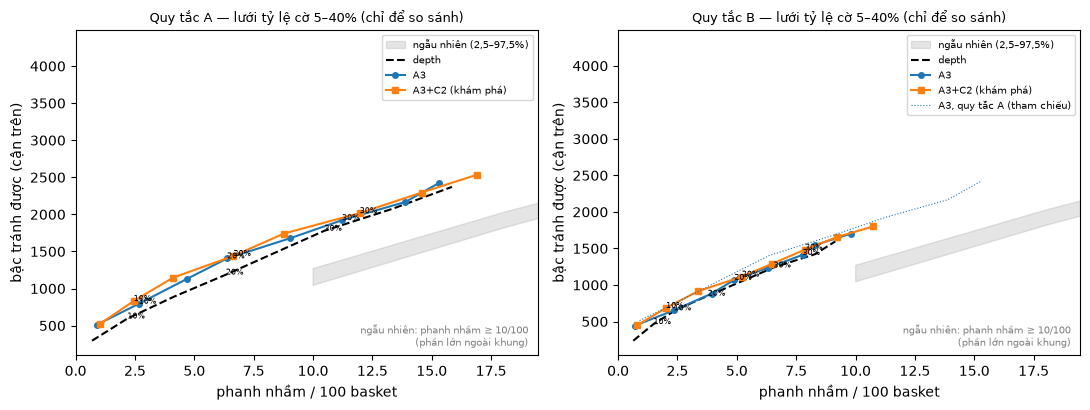

[16 s]

## E. PURGE
Bản chính: train = dòng có t_end < đầu tháng test (nhãn đã biết trước khi test bắt đầu).
Không purge: train = dòng có timestamp < đầu tháng test (gồm dòng có nhãn phụ thuộc tương lai).
Embargo không áp dụng: train luôn trước test, đặc trưng chỉ dùng nến quá khứ nên không có thông tin
tháng test đi vào đặc trưng train; kênh rò rỉ duy nhất là nhãn của basket vắt qua mốc cắt, đã purge.
Dòng bị purge theo fold: {'2026-04': 0, '2026-05': 0, '2026-06': 0, '2026-07': 14, '2026-08': 0}
model  ap_purge  ap_no_purge  max_abs_score_diff  n_purged_total  avoided20_purge  avoided20_no_purge  false20_purge  false20_no_purge
   A0    0.4283       0.4281              0.0044              14             1382                1382            148               148
   A3    0.4541       0.4537              0.0230              14             1417                1413            126               125
A3+C2    0.4749       0.4743              0.0242              14             1573           

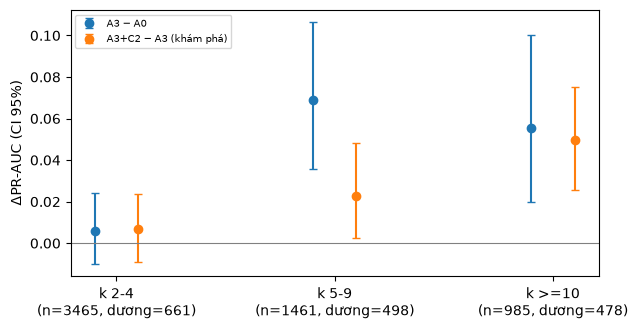

[29 s]

## G. ĐỘ NHẠY (chỉ báo cáo, không dùng chọn mô hình)
                              bien_the    so_sanh    n  delta     lo     hi
                                 chính    A3 − A0 5911 0.0258 0.0090 0.0420
                                 chính A3+C2 − A3 5911 0.0208 0.0099 0.0314
                                 chính A3+C2 − A0 5911 0.0466 0.0280 0.0631
                  (i) chỉ EXACT_UNIQUE    A3 − A0 3657 0.0298 0.0106 0.0477
                  (i) chỉ EXACT_UNIQUE A3+C2 − A3 3657 0.0160 0.0064 0.0263
                  (i) chỉ EXACT_UNIQUE A3+C2 − A0 3657 0.0458 0.0265 0.0652
                    (ii) bỏ ngày 05/08    A3 − A0 5814 0.0248 0.0090 0.0436
                    (ii) bỏ ngày 05/08 A3+C2 − A3 5814 0.0219 0.0090 0.0328
                    (ii) bỏ ngày 05/08 A3+C2 − A0 5814 0.0467 0.0284 0.0664
(iii) trọng số basket (fit + đánh giá)    A3 − A0 5911 0.0130 0.0050 0.0215
(iii) trọng số basket (fit + đánh giá) A3+C2 − A3 5911 0.0096 0.0041 0.0145
(iii) trọng số basket (fit 

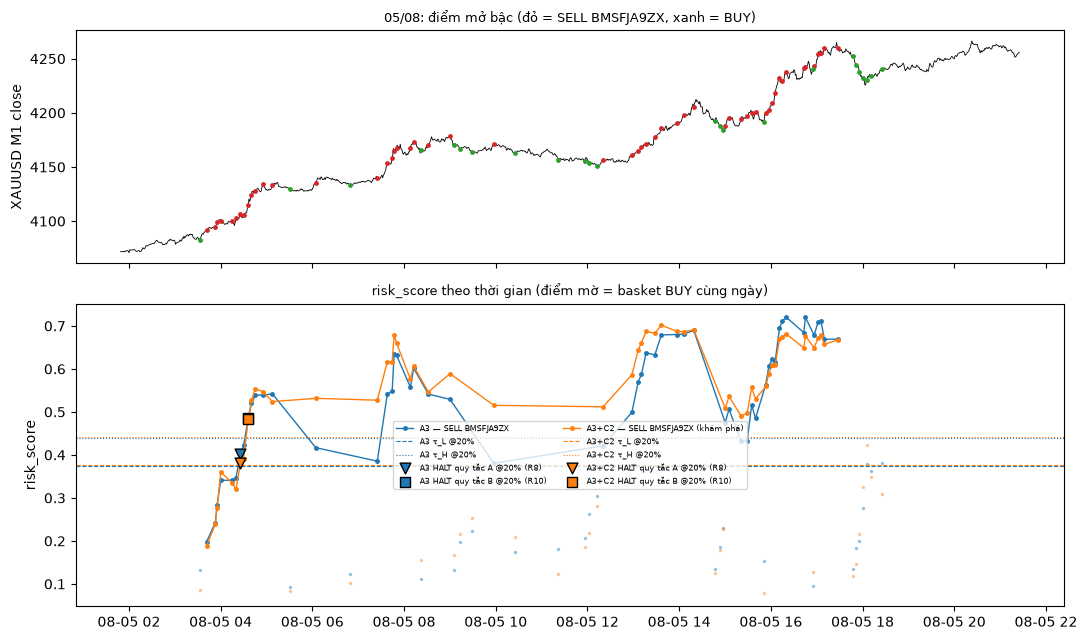


## Z. KIỂM TRA VÀ THỜI GIAN
  [OK] y = (M − k ≥ HORIZON)
  [OK] điểm số/ngưỡng A3 trùng features.walk_forward_m1
  [OK] sim_A trùng evaluate.brake_sim (mọi mô hình/tỷ lệ)
  [OK] A0 là hàm tăng của k trong từng fold (A0 ≡ baseline độ sâu về thứ hạng trong tháng)
  [OK] B không tránh nhiều bậc hơn A ở cùng τ_L (từng basket)
  [OK] train purge không chứa dòng t_end ≥ mốc cắt
Tổng 102 s (bootstrap 94 s, ngẫu nhiên 3 s). Ước tính với n_boot = n_random = 1000: ~1.7 phút.
Kiểm tra: tất cả OK


In [17]:
args = SimpleNamespace(n_boot=1000, n_random=1000, smoke=False)

NB, NR = (20, 20) if args.smoke else (args.n_boot, args.n_random)
SEED = C.SEED
global TAB, FIG
base = C.REPORTS / "smoke" if args.smoke else C.REPORTS     # smoke KHÔNG ghi đè kết quả đầy đủ
TAB, FIG = (base / "tables", base / "figures") if args.smoke else (C.TABLES, C.FIGS)
for d in (base, TAB, FIG):
    Path(d).mkdir(parents=True, exist_ok=True)
log = Tee(base / "g6_report.txt")
pd.set_option("display.width", 220)
pd.set_option("display.max_columns", 40)
t0 = time.time()
log("G6 — QUY TẮC QUYẾT ĐỊNH, ĐỐI CHỨNG, PURGE, PHÂN TẦNG, ĐỘ NHẠY, CASE STUDY")
log(f"{'SMOKE TEST — số liệu KHÔNG dùng cho báo cáo' if args.smoke else 'BẢN ĐẦY ĐỦ'} | "
    f"n_boot = {NB}, n_random = {NR}, seed = {SEED}")
log(f"Chốt trước: RATES = {G.RATES}, GRID = {G.GRID}, m = {G.M_LIMIT}, τ_H = Q(1 − r·{G.TAU_H_FRAC}) "
    f"(độ nhạy r·{G.TAU_H_SENS:.3f}). A3+C2 = KHÁM PHÁ.")
checks = []

section(log, "0. DỮ LIỆU")
s = pd.read_parquet(C.INTERIM / "samples.parquet")
m1 = pd.read_parquet(C.INTERIM / "m1_clean.parquet")
m1["time"] = m1["time"].astype("datetime64[ns]")
bars, full, S = G.build_sets(s, m1)
log(f"samples {len(s):,} | tập đầy đủ (G4/G5) {len(full):,} | tập chung có C2 {len(S):,}")
checks.append(("y = (M − k ≥ HORIZON)", bool((s["y"] == ((s["M"] - s["k"]) >= C.HORIZON)).all())))
log(f"[{time.time() - t0:.0f} s]")

section(log, "A. MÔ HÌNH (walk-forward, purge t_end < đầu tháng test)")
R = {n: G.run_model(S, bars, fs) for n, fs in G.MODELS.items()}
R[G.DEPTH] = G.run_model(S, bars, None)
RF = {n: G.run_model(full, bars, G.MODELS[n]) for n in ("A0", "A3")}
RF[G.DEPTH] = G.run_model(full, bars, None)
ref = R["A0"]["oos"]
for n, r in R.items():
    o = r["oos"]
    assert (o["basket_id"].to_numpy() == ref["basket_id"].to_numpy()).all() and (o["k"].to_numpy() == ref["k"].to_numpy()).all()
# khớp với hàm G4/G5
wf = F.walk_forward_m1(S, bars, G.TEST_MONTHS, G.A3).sort_values(["basket_id", "k"], kind="stable")
same = np.allclose(wf["score"].to_numpy(), R["A3"]["oos"]["score"].to_numpy(), atol=1e-12)
same_thr = np.allclose(wf["thr_20"].to_numpy(), G.thr_train(R["A3"], 0.20), atol=1e-12)
checks.append(("điểm số/ngưỡng A3 trùng features.walk_forward_m1", bool(same and same_thr)))
yv = ref["y"].to_numpy()
log(f"OOS tập chung: {len(ref):,} dòng, dương {int(yv.sum())}, {ref['basket_id'].nunique()} basket, "
    f"{ref['day'].nunique()} ngày | OOS tập đầy đủ: {len(RF['A0']['oos']):,} dòng")
rows = []
for setname, RR in (("chung", R), ("day_du", RF)):
    for n, r in RR.items():
        o = r["oos"]
        rows.append({"tap": setname, "model": n, "n": len(o), "pos": int(o["y"].sum()), "pr_auc": E.pr_auc(o["y"], o["score"])})
apt = pd.DataFrame(rows)
apt.to_csv(TAB / "g6_ap.csv", index=False)
log(apt.round(4).to_string(index=False))
log("Đối chiếu G4/G5 (tập đầy đủ): A0 0,4266; A3 0,4496. Tập chung 15b: A3 0,454.")
pairs = [("chung", "A3", "A0", "chính"), ("chung", "A3+C2", "A3", "khám phá"), ("chung", "A3+C2", "A0", "khám phá"),
         ("day_du", "A3", "A0", "đối chiếu")]
rows = []
for setname, a, b, kind in pairs:
    RR = R if setname == "chung" else RF
    o = RR[a]["oos"]
    bt = timed(T_BOOT, G.boot_ap_delta, o["y"], o["score"], RR[b]["oos"]["score"], o["day"], n_boot=NB, seed=SEED)
    rows.append({"tap": setname, "loai": kind, "so_sanh": f"{a} − {b}", **bt})
dap = pd.DataFrame(rows)
dap.to_csv(TAB / "g6_ap_delta.csv", index=False)
log("\nΔPR-AUC (bootstrap theo ngày, ghép cặp, CI 95%):")
log(dap[["tap", "loai", "so_sanh", "delta", "lo", "hi", "p_pos"]].round(4).to_string(index=False))
bym = pd.DataFrame({n: r["oos"].groupby("fold").apply(lambda d: E.pr_auc(d["y"], d["score"]), include_groups=False)
                    for n, r in R.items()})
bym.to_csv(TAB / "g6_ap_by_month.csv")
log("\nPR-AUC theo tháng (tập chung):\n" + bym.round(4).to_string())
log(f"[{time.time() - t0:.0f} s]")

section(log, "C. PHANH — BẢN TRIỂN KHAI (ngưỡng = phân vị điểm số TRAIN của từng fold)")
log("Quy tắc A: HALT khi score ≥ τ_L. Quy tắc B: τ_L chung với A, τ_H = Q_train(1 − r/2); LIMIT cho mở "
    f"tối đa {G.M_LIMIT} bậc rồi HALT. Đối chứng cùng số dòng gắn cờ thực tế mỗi tháng: độ sâu k (phá hòa "
    "ngẫu nhiên) và ngẫu nhiên.")
P = G.make_panel(ref)
rng_tb = np.random.default_rng(SEED)
rows, drow, keep = [], [], {}
mismatch = 0
for setname, RR in (("chung", R), ("day_du", RF)):
    PP = P if setname == "chung" else G.make_panel(RR["A0"]["oos"])
    for n, r in RR.items():
        o = r["oos"]
        sc = o["score"].to_numpy()
        for q in G.RATES:
            fl = sc >= G.thr_train(r, q)
            ra = G.sim_A(PP, fl)
            bs = E.brake_sim(o, G.thr_train(r, q))
            mismatch += int(bs["avoided_total"] != ra["avoided"].sum() or bs["false_halts"] != ra["false"].sum()
                            or bs["deep_caught"] != ra["caught"].sum())
            rows.append({"tap": setname, "model": n, "rule": "A", "target": q, **G.summarize(PP, ra)})
            for frac, lab in ((G.TAU_H_FRAC, "B"), (G.TAU_H_SENS, "B_r/3 (độ nhạy)")):
                fh = sc >= G.thr_train(r, q * frac)
                rb = G.sim_B(PP, fl, fh & fl)
                rows.append({"tap": setname, "model": n, "rule": lab, "target": q, **G.summarize(PP, rb)})
                if setname == "chung" and lab == "B":
                    keep[(n, "B", q)] = rb
                    drow.append({"so_sanh": f"{n}: B − A", "target": q,
                                 **timed(T_BOOT, G.boot_brake_delta, PP, rb, ra, n_boot=NB, seed=SEED)})
            if setname != "chung" or n == G.DEPTH:
                continue
            keep[(n, "A", q)] = ra
            nf = G.n_flagged(PP, fl)
            rd = G.sim_A(PP, G.topn_flags(PP, o["k"].to_numpy(), nf, rng_tb))
            rows.append({"tap": setname, "model": f"đối chứng độ sâu ({n})", "rule": "A", "target": q, **G.summarize(PP, rd)})
            drow.append({"so_sanh": f"{n} − độ sâu cùng số cờ", "target": q,
                         **timed(T_BOOT, G.boot_brake_delta, PP, ra, rd, n_boot=NB, seed=SEED)})
            rr = timed(T_RAND, G.random_A, PP, nf, NR, SEED)
            rows.append({"tap": setname, "model": f"ngẫu nhiên ({n}), trung bình", "rule": "A", "target": q,
                         "avoided_total": rr["avoided"].mean(), "false_halts": rr["false"].mean(),
                         "deep_caught": rr["caught"].mean(), "flag_rows_pct": 100 * nf.sum() / PP["N"],
                         "pct_model_avoided": G.pct_in(rr["avoided"], ra["avoided"].sum()),
                         "pct_model_false": G.pct_in(rr["false"], ra["false"].sum()),
                         "pct_model_caught": G.pct_in(rr["caught"], ra["caught"].sum())})
    for K in C.RULE_K:
        o = RR[G.DEPTH]["oos"]
        rows.append({"tap": setname, "model": f"k ≥ {K} (cố định)", "rule": "A", "target": np.nan,
                     **G.summarize(PP, G.sim_A(PP, o["k"].to_numpy() >= K))})
checks.append(("sim_A trùng evaluate.brake_sim (mọi mô hình/tỷ lệ)", mismatch == 0))
o0 = R["A0"]["oos"]
mono = all(bool((d.groupby("k")["score"].agg(["min", "max"]).pipe(
    lambda g: (g["min"].to_numpy()[1:] > g["max"].to_numpy()[:-1]).all() and np.allclose(g["min"], g["max"]))))
    for _, d in o0.groupby("fold"))
checks.append(("A0 là hàm tăng của k trong từng fold (A0 ≡ baseline độ sâu về thứ hạng trong tháng)", mono))
bt = pd.DataFrame(rows)
bt.to_csv(TAB / "g6_brake_deploy.csv", index=False)
show = bt[(bt["tap"] == "chung") & bt["target"].isin([0.2])]
log("Trích @20% (tập chung; đủ trong g6_brake_deploy.csv):")
log(show[["model", "rule", "flag_rows_pct", "halted_pct", "avoided_total", "false_halts", "deep_caught"]].round(1).to_string(index=False))
dbt = pd.DataFrame(drow)
dbt.to_csv(TAB / "g6_brake_deploy_delta.csv", index=False)
log(f"Δ bootstrap: g6_brake_deploy_delta.csv ({len(dbt)} dòng). [{time.time() - t0:.0f} s]")

section(log, "D. ĐƯỜNG CONG CÔNG BẰNG (cùng tỷ lệ cờ thực tế; phân vị điểm số THÁNG TEST — chỉ để so sánh)")
rows, drow = [], []
fair = {}
for n in (G.DEPTH, "A0", "A3", "A3+C2"):
    sc = R[n]["oos"]["score"].to_numpy()
    for q in G.GRID:
        rg = np.random.default_rng(SEED)          # cùng phá hòa cho mọi mô hình
        fl = G.topn_flags(P, sc, G.n_at_rate(P, q), rg)
        rg = np.random.default_rng(SEED)
        fh = G.topn_flags(P, sc, G.n_at_rate(P, q * G.TAU_H_FRAC), rg) & fl
        ra, rb = G.sim_A(P, fl), G.sim_B(P, fl, fh)
        fair[(n, "A", q)], fair[(n, "B", q)] = ra, rb
        rows.append({"model": n, "rule": "A", "rate": q, **G.summarize(P, ra)})
        rows.append({"model": n, "rule": "B", "rate": q, **G.summarize(P, rb)})
rand_band = {}
for q in G.GRID:
    rr = timed(T_RAND, G.random_A, P, G.n_at_rate(P, q), NR, SEED)
    rand_band[q] = rr
    rows.append({"model": "ngẫu nhiên", "rule": "A", "rate": q, "avoided_total": rr["avoided"].mean(),
                 "false_halts": rr["false"].mean(), "false_per100": 100 * rr["false"].mean() / len(P["starts"]),
                 "deep_caught": rr["caught"].mean(),
                 "avoided_p2.5": np.percentile(rr["avoided"], 2.5), "avoided_p97.5": np.percentile(rr["avoided"], 97.5),
                 "false_p2.5": np.percentile(rr["false"], 2.5), "false_p97.5": np.percentile(rr["false"], 97.5)})
ft = pd.DataFrame(rows)
for n in ("A3", "A3+C2"):
    for q in G.GRID:
        r_ = fair[(n, "A", q)]
        i = ft.index[(ft["model"] == n) & (ft["rule"] == "A") & (ft["rate"] == q)]
        ft.loc[i, "pct_vs_random_avoided"] = G.pct_in(rand_band[q]["avoided"], r_["avoided"].sum())
        ft.loc[i, "pct_vs_random_false"] = G.pct_in(rand_band[q]["false"], r_["false"].sum())
ft.to_csv(TAB / "g6_brake_fair.csv", index=False)
same_a0 = all((fair[("A0", "A", q)]["k_halt"] == fair[(G.DEPTH, "A", q)]["k_halt"]).all() for q in G.GRID)
log(f"A0 trùng đối chứng độ sâu trên toàn lưới: {same_a0} (thứ hạng giống nhau, cùng phá hòa)")
for q in G.RATES:
    for a, b, lab in (("A3", G.DEPTH, "A3 − độ sâu (A)"), ("A3+C2", G.DEPTH, "A3+C2 − độ sâu (A)"),
                      ("A3+C2", "A3", "A3+C2 − A3 (A)")):
        drow.append({"so_sanh": lab, "rate": q, **timed(T_BOOT, G.boot_brake_delta, P, fair[(a, "A", q)], fair[(b, "A", q)],
                                                        n_boot=NB, seed=SEED)})
    for n in (G.DEPTH, "A3", "A3+C2"):
        drow.append({"so_sanh": f"{n}: B − A", "rate": q, **timed(T_BOOT, G.boot_brake_delta, P, fair[(n, "B", q)],
                                                               fair[(n, "A", q)], n_boot=NB, seed=SEED)})
fd = pd.DataFrame(drow)
fd.to_csv(TAB / "g6_brake_fair_delta.csv", index=False)
log("Δ @10/20/30% (bootstrap theo ngày; d_* = tổng chênh, âm ở d_false là tốt):")
log(fd[["so_sanh", "rate", "d_avoided", "d_avoided_lo", "d_avoided_hi", "d_false", "d_false_lo", "d_false_hi"]]
    .round(1).to_string(index=False))
viol = sum(int((fair[(n, "B", q)]["avoided"] > fair[(n, "A", q)]["avoided"]).sum())
           for n in (G.DEPTH, "A0", "A3", "A3+C2") for q in G.GRID)
checks.append(("B không tránh nhiều bậc hơn A ở cùng τ_L (từng basket)", viol == 0))

fig, ax = plt.subplots(1, 2, figsize=(11, 4.2))
nb = len(P["starts"])
for j, rule in enumerate(("A", "B")):
    a = ax[j]
    rb = ft[ft["model"] == "ngẫu nhiên"]
    a.fill_between(100 * rb["false_halts"] / nb, rb["avoided_p2.5"], rb["avoided_p97.5"], color="grey", alpha=0.2,
                   label="ngẫu nhiên (2,5–97,5%)")
    for n, st in ((G.DEPTH, "k--"), ("A3", "C0-o"), ("A3+C2", "C1-s")):
        d = ft[(ft["model"] == n) & (ft["rule"] == rule)]
        a.plot(d["false_per100"], d["avoided_total"], st, ms=4, label=n + (" (khám phá)" if n == "A3+C2" else ""))
        for _, rr_ in d[d["rate"].isin(G.RATES)].iterrows():
            a.annotate(f"{int(round(100 * rr_['rate']))}%", (rr_["false_per100"], rr_["avoided_total"]), fontsize=6)
    if rule == "B":
        d = ft[(ft["model"] == "A3") & (ft["rule"] == "A")]
        a.plot(d["false_per100"], d["avoided_total"], "C0:", lw=0.8, label="A3, quy tắc A (tham chiếu)")
    xmax = 1.15 * ft.loc[ft["model"] != "ngẫu nhiên", "false_per100"].max()
    a.set_xlim(0, xmax)
    a.text(0.98, 0.03, f"ngẫu nhiên: phanh nhầm ≥ {100 * rb['false_halts'].min() / nb:.0f}/100\n(phần lớn ngoài khung)",
           transform=a.transAxes, ha="right", fontsize=7, color="grey")
    a.set_title(f"Quy tắc {rule} — lưới tỷ lệ cờ 5–40% (chỉ để so sánh)", fontsize=9)
    a.set_xlabel("phanh nhầm / 100 basket")
    a.set_ylabel("bậc tránh được (cận trên)")
    a.legend(fontsize=7)
fig.tight_layout()
fig.savefig(FIG / "g6_brake_curve.png", dpi=130)
display(fig)
plt.close(fig)
log(f"[{time.time() - t0:.0f} s]")


section(log, "E. PURGE")
log("Bản chính: train = dòng có t_end < đầu tháng test (nhãn đã biết trước khi test bắt đầu).\n"
    "Không purge: train = dòng có timestamp < đầu tháng test (gồm dòng có nhãn phụ thuộc tương lai).\n"
    "Embargo không áp dụng: train luôn trước test, đặc trưng chỉ dùng nến quá khứ nên không có thông tin\n"
    "tháng test đi vào đặc trưng train; kênh rò rỉ duy nhất là nhãn của basket vắt qua mốc cắt, đã purge.")
rows = []
for n, fs in list(G.MODELS.items()):
    rn = G.run_model(S, bars, fs, purge=False)
    o, op = rn["oos"], R[n]["oos"]
    r20n = G.sim_A(P, o["score"].to_numpy() >= G.thr_train(rn, 0.2))
    r20p = keep[(n, "A", 0.2)]
    rows.append({"model": n, "ap_purge": E.pr_auc(op["y"], op["score"]), "ap_no_purge": E.pr_auc(o["y"], o["score"]),
                 "max_abs_score_diff": float(np.abs(o["score"].to_numpy() - op["score"].to_numpy()).max()),
                 "n_purged_total": sum(v["n_purged"] for v in R[n]["info"].values()),
                 "avoided20_purge": int(r20p["avoided"].sum()), "avoided20_no_purge": int(r20n["avoided"].sum()),
                 "false20_purge": int(r20p["false"].sum()), "false20_no_purge": int(r20n["false"].sum())})
pt = pd.DataFrame(rows)
pt.to_csv(TAB / "g6_purge.csv", index=False)
log("Dòng bị purge theo fold: " + str({m: v["n_purged"] for m, v in R["A3"]["info"].items()}))
log(pt.round(4).to_string(index=False))
checks.append(("train purge không chứa dòng t_end ≥ mốc cắt",
               all(v["n_train_t_end_ge_cut"] == 0 for r in R.values() for v in r["info"].values())))


section(log, "F. PHÂN TẦNG k VÀ HỆ SỐ CHUẨN HÓA")
rows = []
kk = ref["k"].to_numpy()
for lo, hi, lab in G.K_BINS:
    msk = G.kbin_mask(kk, lo, hi)
    base = {"k": lab, "n": int(msk.sum()), "pos": int(yv[msk].sum()), "n_basket": ref.loc[msk, "basket_id"].nunique()}
    for n in ("A0", "A3", "A3+C2"):
        base[f"ap_{n}"] = E.pr_auc(yv[msk], R[n]["oos"]["score"].to_numpy()[msk])
    for a, b in (("A3", "A0"), ("A3+C2", "A3")):
        bb = timed(T_BOOT, G.boot_ap_delta, yv[msk], R[a]["oos"]["score"].to_numpy()[msk],
                   R[b]["oos"]["score"].to_numpy()[msk], ref["day"].to_numpy()[msk], n_boot=NB, seed=SEED)
        base[f"d_{a}-{b}"], base[f"lo_{a}-{b}"], base[f"hi_{a}-{b}"] = bb["delta"], bb["lo"], bb["hi"]
    rows.append(base)
stt = pd.DataFrame(rows)
stt.to_csv(TAB / "g6_strata_k.csv", index=False)
log(stt.round(4).to_string(index=False))
log("Lưu ý: trong mỗi tầng A0 vẫn chỉ xếp hạng theo k; ở k = 2–4 chỉ có 3 mức nên AP(A0) gần tỷ lệ dương của tầng.")
ct = G.coef_table({n: R[n] for n in G.MODELS})
ct.to_csv(TAB / "g6_coef.csv")
log("\nHệ số logistic chuẩn hóa (StandardScaler fit trên train từng fold):\n" + ct.round(3).to_string())
fig, ax = plt.subplots(figsize=(6.5, 3.4))
x = np.arange(len(stt))
for j, (a, b, c) in enumerate((("A3", "A0", "C0"), ("A3+C2", "A3", "C1"))):
    d = stt[f"d_{a}-{b}"]
    ax.errorbar(x + (j - 0.5) * 0.2, d, yerr=[d - stt[f"lo_{a}-{b}"], stt[f"hi_{a}-{b}"] - d], fmt="o", color=c,
                capsize=3, label=f"{a} − {b}" + (" (khám phá)" if a == "A3+C2" else ""))
ax.axhline(0, color="grey", lw=0.8)
ax.set_xticks(x, [f"k {r.k}\n(n={r.n}, dương={r.pos})" for r in stt.itertuples()])
ax.set_ylabel("ΔPR-AUC (CI 95%)")
ax.legend(fontsize=7)
fig.tight_layout()
fig.savefig(FIG / "g6_strata_k.png", dpi=130)
display(fig)
plt.close(fig)
log(f"[{time.time() - t0:.0f} s]")

section(log, "G. ĐỘ NHẠY (chỉ báo cáo, không dùng chọn mô hình)")
rows = []

def sens_rows(variant, RR, w=None, mask=None, note=""):
    o0 = RR["A0"]["oos"]
    msk = np.ones(len(o0), bool) if mask is None else mask
    yy, dd = o0["y"].to_numpy()[msk], o0["day"].to_numpy()[msk]
    ww = None if w is None else w[msk]
    out = []
    for a, b in (("A3", "A0"), ("A3+C2", "A3"), ("A3+C2", "A0")):
        bb = timed(T_BOOT, G.boot_ap_delta, yy, RR[a]["oos"]["score"].to_numpy()[msk], RR[b]["oos"]["score"].to_numpy()[msk],
                   dd, w=ww, n_boot=NB, seed=SEED)
        out.append({"bien_the": variant, "so_sanh": f"{a} − {b}", "n": int(msk.sum()), "pos": int(yy.sum()),
                    "ap_a": bb["ap_a"], "ap_b": bb["ap_b"], "delta": bb["delta"], "lo": bb["lo"], "hi": bb["hi"], "ghi_chu": note})
    return out

rows += sens_rows("chính", R)
eu = S[S["timestamp_quality"] == "EXACT_UNIQUE"]
REU = {n: G.run_model(eu, bars, fs) for n, fs in G.MODELS.items()}
rows += sens_rows("(i) chỉ EXACT_UNIQUE", REU, note="train và test đều lọc; basket có thể mất dòng giữa chừng")
rows += sens_rows("(ii) bỏ ngày 05/08", R, mask=(ref["day"] != G.CASE_DAY).to_numpy(),
                  note="05/08 thuộc tháng test 08, không nằm trong train của fold nào → chỉ bỏ khỏi đánh giá")
RW = {n: G.run_model(S, bars, fs, weight=True) for n, fs in G.MODELS.items()}
rows += sens_rows("(iii) trọng số basket (fit + đánh giá)", RW, w=G.basket_weight(RW["A0"]["oos"]))
rows += sens_rows("(iv) trọng số k² khi đánh giá", R, w=(ref["k"].to_numpy(float) ** 2),
                  note="GIẢ ĐỊNH lot phẳng: mức tiếp xúc ∝ k²; mô hình không đổi")
sens = pd.DataFrame(rows)

brows = []
for variant, RR in (("(i) EXACT_UNIQUE", REU), ("(iii) trọng số basket", RW)):
    PP = G.make_panel(RR["A0"]["oos"])
    for n in ("A0", "A3", "A3+C2"):
        o = RR[n]["oos"]
        brows.append({"bien_the": variant, "model": n,
                      **G.summarize(PP, G.sim_A(PP, o["score"].to_numpy() >= G.thr_train(RR[n], 0.2)))})
msk = (ref["day"] != G.CASE_DAY).to_numpy()
Pd = G.make_panel(ref[msk].reset_index(drop=True))
for n in ("A0", "A3", "A3+C2"):
    o = R[n]["oos"]
    brows.append({"bien_the": "(ii) bỏ 05/08", "model": n,
                  **G.summarize(Pd, G.sim_A(Pd, (o["score"].to_numpy() >= G.thr_train(R[n], 0.2))[msk]))})
sens.to_csv(TAB / "g6_sens.csv", index=False)
pd.DataFrame(brows).to_csv(TAB / "g6_sens_brake20.csv", index=False)
log(sens[["bien_the", "so_sanh", "n", "delta", "lo", "hi"]].round(4).to_string(index=False))
log(f"Phanh @20% theo biến thể: g6_sens_brake20.csv. [{time.time() - t0:.0f} s]")


section(log, "H. CASE STUDY 05/08 (ngưỡng triển khai fold 08)")
day = ref["day"] == G.CASE_DAY
case_b = ref.loc[day, ["basket_id", "side", "M"]].drop_duplicates("basket_id")
sell = case_b[case_b["basket_id"] == G.CASE_BASKET]
buys = case_b[case_b["side"].astype(str).str.upper() == "BUY"]
log(f"Basket ngày 05/08 trong OOS: {len(case_b)} | SELL {G.CASE_BASKET}: "
    f"{'có' if len(sell) else 'KHÔNG CÓ'} | BUY: {len(buys)}")
nrow = int((s["basket_id"] == G.CASE_BASKET).sum())
nkeep = int((ref["basket_id"] == G.CASE_BASKET).sum())
log(f"{G.CASE_BASKET}: {nrow} dòng trong samples, {nkeep} dòng trong tập chung (dòng thiếu không có điểm số).")
sel = set(case_b["basket_id"]) if len(sell) == 0 else set(sell["basket_id"]) | set(buys["basket_id"])
bidx = {b: i for i, b in enumerate(P["basket"])}
rows = []
for b in sorted(sel):
    i = bidx[b]
    for n in (G.DEPTH, "A3", "A3+C2"):
        for q in G.RATES:
            for rule in ("A", "B"):
                rr_ = keep.get((n, rule, q))
                if rr_ is None:     # depth A
                    rr_ = G.sim_A(P, R[n]["oos"]["score"].to_numpy() >= G.thr_train(R[n], q))
                rows.append({"basket_id": b, "side": case_b.set_index("basket_id").loc[b, "side"],
                             "M": int(P["Mb"][i]), "model": n, "rule": rule, "target": q,
                             "k_halt": int(rr_["k_halt"][i]) if rr_["halted"][i] else None,
                             "avoided": int(rr_["avoided"][i]), "phanh_nham": bool(rr_["false"][i])})
cs = pd.DataFrame(rows)
cs.to_csv(TAB / "g6_case_0805.csv", index=False)
if len(sell):
    log(cs[cs["basket_id"] == G.CASE_BASKET].pivot_table(index=["model", "rule"], columns="target", values="k_halt",
                                                          aggfunc="first").to_string())
    log("(ô trống = không HALT)")
fig, ax = plt.subplots(2, 1, figsize=(11, 6.5), sharex=True, gridspec_kw={"height_ratios": [1, 1.3]})
t_lo = ref.loc[day, "timestamp"].min() - pd.Timedelta(minutes=30)
t_hi = ref.loc[day, "timestamp"].max() + pd.Timedelta(minutes=30)
mm = m1[(m1["time"] >= t_lo) & (m1["time"] <= t_hi)]
ax[0].plot(mm["time"], mm["close"], color="k", lw=0.6)
for b in sel:
    d = ref[ref["basket_id"] == b]
    isb = str(case_b.set_index("basket_id").loc[b, "side"]).upper() == "BUY"
    px = np.interp(d["timestamp"].astype("int64"), mm["time"].astype("int64"), mm["close"])
    ax[0].scatter(d["timestamp"], px, s=6, color="C2" if isb else "C3", zorder=3)
ax[0].set_ylabel("XAUUSD M1 close")
ax[0].set_title("05/08: điểm mở bậc (đỏ = SELL " + G.CASE_BASKET + ", xanh = BUY)", fontsize=9)
for n, c in (("A3", "C0"), ("A3+C2", "C1")):
    o = R[n]["oos"]
    for b in sel:
        d = o[o["basket_id"] == b]
        if b == G.CASE_BASKET:
            ax[1].plot(d["timestamp"], d["score"], "-o", color=c, ms=2.5, lw=1,
                       label=f"{n} — SELL {G.CASE_BASKET}" + (" (khám phá)" if n == "A3+C2" else ""))
        else:
            ax[1].plot(d["timestamp"], d["score"], ".", color=c, ms=3, alpha=0.35)
    tl = G.thr_train(R[n], 0.2)[(o["fold"] == "2026-08").to_numpy()][0]
    th = G.thr_train(R[n], 0.2 * G.TAU_H_FRAC)[(o["fold"] == "2026-08").to_numpy()][0]
    ax[1].axhline(tl, color=c, ls="--", lw=0.8, label=f"{n} τ_L @20%")
    ax[1].axhline(th, color=c, ls=":", lw=0.8, label=f"{n} τ_H @20%")
    for rule, mk in (("A", "v"), ("B", "s")):
        rr_ = keep[(n, rule, 0.2)]
        if len(sell) and rr_["halted"][bidx[G.CASE_BASKET]]:
            kh = rr_["k_halt"][bidx[G.CASE_BASKET]]
            d = o[(o["basket_id"] == G.CASE_BASKET) & (o["k"] == kh)]
            tt = d["timestamp"].iloc[0] if len(d) else o.loc[(o["basket_id"] == G.CASE_BASKET) & (o["k"] < kh), "timestamp"].max()
            ax[1].scatter([tt], [d["score"].iloc[0] if len(d) else tl], marker=mk, s=60, color=c, edgecolor="k", zorder=4,
                          label=f"{n} HALT quy tắc {rule} @20% (R{kh})")
ax[1].set_ylabel("risk_score")
ax[1].set_title("risk_score theo thời gian (điểm mờ = basket BUY cùng ngày)", fontsize=9)
ax[1].legend(fontsize=6, ncol=2)
fig.tight_layout()
fig.savefig(FIG / "g6_case_0805.png", dpi=130)
display(fig)
plt.close(fig)


section(log, "Z. KIỂM TRA VÀ THỜI GIAN")
for n, ok in checks:
    log(f"  [{'OK' if ok else '!!'}] {n}")
tot = time.time() - t0
est = (tot - T_BOOT[0] - T_RAND[0]) + T_BOOT[0] * 1000 / max(NB, 1) + T_RAND[0] * 1000 / max(NR, 1)
log(f"Tổng {tot:.0f} s (bootstrap {T_BOOT[0]:.0f} s, ngẫu nhiên {T_RAND[0]:.0f} s). "
    f"Ước tính với n_boot = n_random = 1000: ~{est / 60:.1f} phút.")
log("Kiểm tra: " + ("tất cả OK" if all(ok for _, ok in checks) else "!! CÓ LỖI"))